## KNN

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

x =rfm_original[["recency","frequency","monetary"]]
y =rfm_original["Cluster"]


x_train ,x_test ,y_train ,y_test =train_test_split(
    x,
    y,
    random_state=42,
    test_size=0.2
)

pipeline_kNN =Pipeline([
    ("scaler",StandardScaler()),
    ("knn",KNeighborsClassifier())
])

param_grid ={
    "knn__n_neighbors": [3,5,7,9,11,15,21],
    "knn__weights": ["uniform","distance"],
    "knn__metric": ["euclidean","manhattan"]
}

from sklearn.model_selection import cross_val_score

cv =cross_val_score(
    n_splits =5,
    shuffle=True,
    random_state=42
)




NameError: name 'rfm_original' is not defined

## Partie 10 — Nouveau client.

In [72]:
import pandas as  pd

rf_loaded = joblib.load("rfm_random_forest.joblib")
nouveau_client =pd.DataFrame({
    "recency" :[1],
    "frequency":[50],
    "monetary" :[10000]
})
prediction= rf_loaded.predict(nouveau_client)
print("Cluster predit :", prediction[0])


Cluster predit : 0


## Partie 9 — Importance des variables


In [51]:
importance = pd.DataFrame({
    "Variable": ["recency","frequency","monetary"],
    "Importance": rf_classifier.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=True
)

print(importance)

    Variable  Importance
0    recency    0.316847
2   monetary    0.337969
1  frequency    0.345184


## Partie 8 — Évaluation

In [50]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

accuracy = accuracy_score(y_test ,y_pred)
print("Accuracy",accuracy)
print(classification_report(y_test, y_pred))

Accuracy 0.9861751152073732
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       157
           1       0.99      0.99      0.99       377
           2       0.98      0.98      0.98       334

    accuracy                           0.99       868
   macro avg       0.99      0.99      0.99       868
weighted avg       0.99      0.99      0.99       868



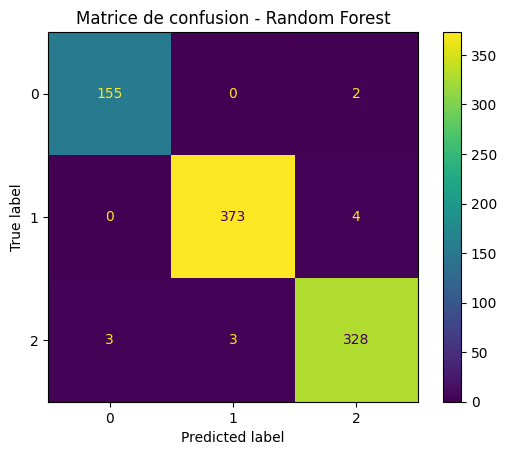

In [92]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()

plt.title("Matrice de confusion - Random Forest")
plt.show()

## Partie 7 — Classification avec Random Forest

In [49]:
from sklearn.ensemble import  RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
import joblib

x =rfm_original.drop(columns=["Cluster"])
y =rfm_original["Cluster"]

x_train,x_test ,y_train ,y_test=train_test_split(
    x ,
    y,
    test_size =0.2,
    random_state =42
)

rf_classifier =RandomForestClassifier(
    n_estimators=100 ,
    random_state=42,
    n_jobs =-1
)

score =cross_val_score(
    rf_classifier,
    x_train ,
    y_train,
    cv=5
)

rf_classifier.fit(x_train,y_train)
y_pred =rf_classifier.predict(x_test)

joblib.dump(
    rf_classifier,
    "rfm_random_forest.joblib"
)



['rfm_random_forest.joblib']

## Partie 6 — Visualisation avec PCA

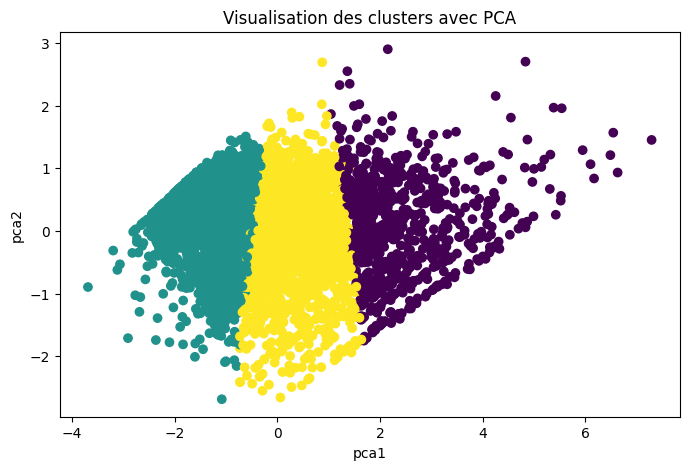

In [51]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca =PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

plt.figure(figsize=(8,5))

plt.scatter(rfm_pca[:,0],rfm_pca[:,1] ,c=rfm_original["Cluster"])

plt.title("Visualisation des clusters avec PCA")
plt.xlabel("pca1")
plt.ylabel("pca2")
plt.show()

## Partie 5:Profiling et inerpretation metier

In [50]:
profil_clusters =rfm_original.groupby("Cluster").agg(
    total_client =("recency","size"),
    recency_moyenne =("recency","mean"),
    frequency_moyenne =("frequency","mean"),
    monetary_moyenne =("monetary","mean"),
    Chiffre_affaire =("monetary" ,"sum")
)
profil_clusters["pourcentage_clients"] =(
    profil_clusters["total_client"]  /len(rfm_original) * 100
)

profil_clusters["contribution_ca"] = (
    profil_clusters["Chiffre_affaire"] / rfm_original["monetary"].sum() * 100
)
profil_clusters["Profil"] =[
    "Récents, fréquents, dépensent beaucoup",
    "Moins récents, peu fréquents, dépensent peu",
    "Profil intermédiaire"]
profil_clusters


,total_client,recency_moyenne,frequency_moyenne,monetary_moyenne,Chiffre_affaire,pourcentage_clients,contribution_ca,Profil
Cluster,,,,,,,,
0,769,17.062419,13.348505,7898.462003,6073917.280,17.727063,68.344486,"Récents, fréquents, dépensent beaucoup"
1,1872,167.358440,1.352030,360.996448,675785.351,43.153527,7.604022,"Moins récents, peu fréquents, dépensent peu"
2,1697,44.199764,3.380082,1259.579412,2137506.263,39.119410,24.051491,Profil intermédiaire


## Partie 4 — Segmentation avec K-Means

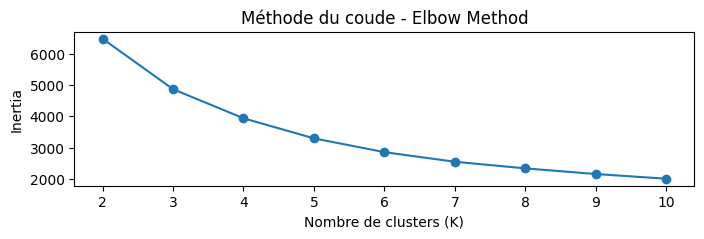

In [47]:
## 4.1 :Recherche de K
# methode du coude (elbow)
from  sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias =[]
for k in range(2,11):
    Kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    Kmeans.fit(rfm_scaled)
    inertias.append(Kmeans.inertia_)
plt.figure(figsize=(8,2))
plt.plot(range(2,11),inertias,marker="o")
plt.title("Méthode du coude - Elbow Method")
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertia")
plt.show()


In [48]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans 

silhouetteScore =[]
for i in range(2,11):
    Kmeans =KMeans(n_clusters=i,random_state=42,n_init=10)
    labels =Kmeans.fit_predict(rfm_scaled)
    score =silhouette_score(rfm_scaled,labels)
    silhouetteScore.append(
        score
    )
    
print(silhouetteScore)

[np.float64(0.4328265515350663), np.float64(0.3365174636950013), np.float64(0.337517049212612), np.float64(0.3162001336222631), np.float64(0.3124091056438892), np.float64(0.30918598433785954), np.float64(0.30327504528060134), np.float64(0.281084500299107), np.float64(0.27665851725435564)]


In [49]:
from sklearn.cluster import KMeans
Kmeans =KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm_original["Cluster"]=Kmeans.fit_predict(rfm_scaled)

rfm_original.groupby("Cluster")[["recency", "frequency", "monetary"]].mean()


,recency,frequency,monetary
Cluster,,,
0,17.062419,13.348505,7898.462003
1,167.358440,1.352030,360.996448
2,44.199764,3.380082,1259.579412


## Partie 3 — Préparation des variables

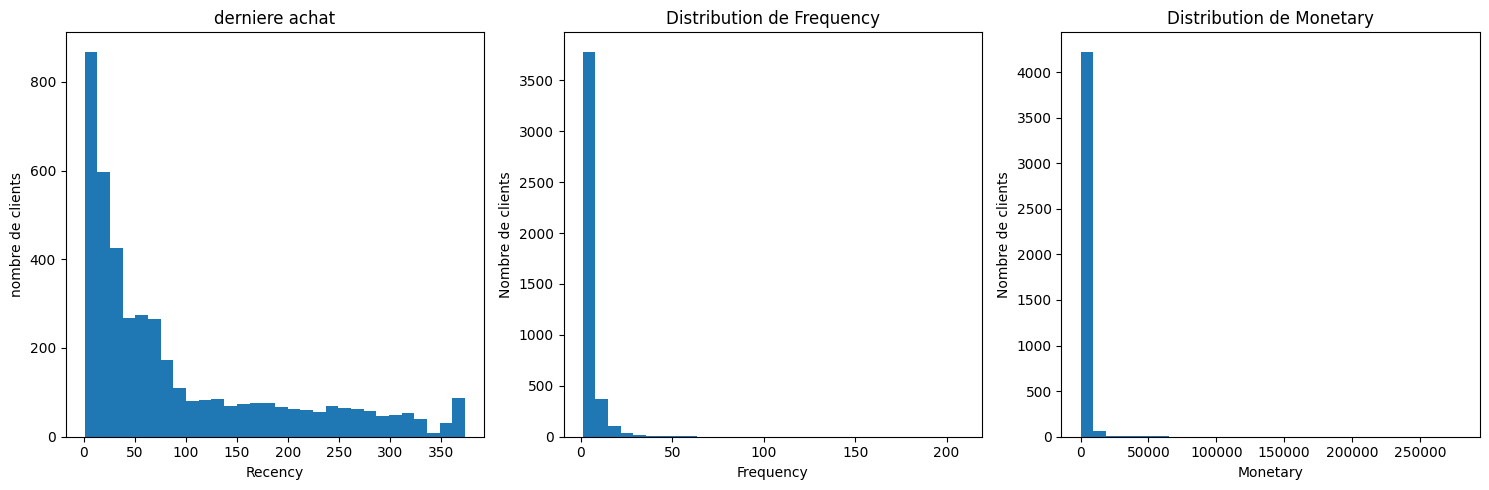

In [43]:
import matplotlib.pyplot as plt

fig ,axes =plt.subplots(1,3,figsize=(15,5))
axes[0].hist(rfm["recency"],bins=30)
axes[0].set_title("derniere achat")
axes[0].set_xlabel("Recency")
axes[0].set_ylabel("nombre de clients")

axes[1].hist(rfm["frequency"], bins=30)
axes[1].set_title("Distribution de Frequency")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("Nombre de clients")

# Monetary
axes[2].hist(rfm["monetary"], bins=30)
axes[2].set_title("Distribution de Monetary")
axes[2].set_xlabel("Monetary")
axes[2].set_ylabel("Nombre de clients")

plt.tight_layout()
plt.show()


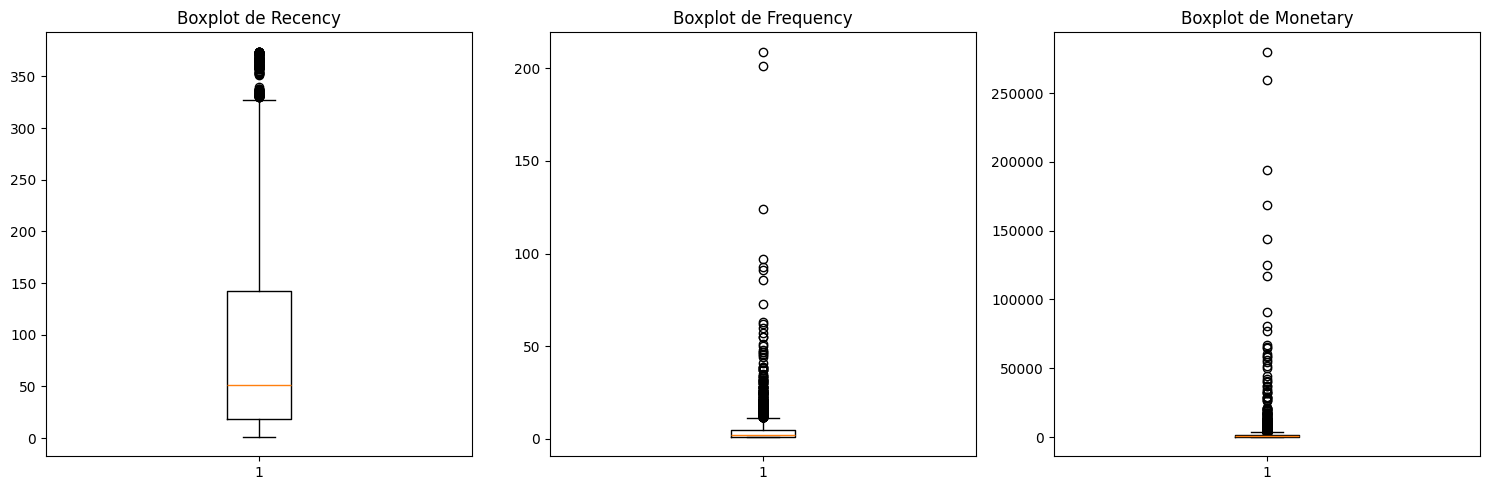

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Recency
axes[0].boxplot(rfm["recency"])
axes[0].set_title("Boxplot de Recency")

# Frequency
axes[1].boxplot(rfm["frequency"])
axes[1].set_title("Boxplot de Frequency")

# Monetary
axes[2].boxplot(rfm["monetary"])
axes[2].set_title("Boxplot de Monetary")

plt.tight_layout()
plt.show()

In [45]:
rfm[["recency", "frequency", "monetary"]].skew()

,0
recency,1.246048
frequency,12.067031
monetary,19.339368


In [46]:
import numpy as np
from sklearn.preprocessing import StandardScaler

rfm_original =rfm.copy()
rfm_log =rfm[["recency" ,"frequency","monetary"]].copy()

rfm_log =np.log1p(rfm_log)

scaler =StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled =pd.DataFrame(
    rfm_scaled,
    columns=rfm_log.columns,
    index=rfm_log.index
)





## constructions des indicateurs RFM

In [39]:
## Recency
print(df["InvoiceDate"].dtype)
print(df["InvoiceDate"].max())
reference_date =df["InvoiceDate"].max() + pd.Timedelta(days= 1)
print(reference_date)
derniere_achat =df.groupby("CustomerID")["InvoiceDate"].max()
recency = (reference_date - derniere_achat).dt.days
print(recency)



datetime64[ns]
2011-12-09 12:50:00
2011-12-10 12:50:00
CustomerID
12346.0    326
12347.0      2
12348.0     75
12349.0     19
12350.0    310
          ... 
18280.0    278
18281.0    181
18282.0      8
18283.0      4
18287.0     43
Name: InvoiceDate, Length: 4338, dtype: int64


In [40]:
# frecency
frequency = df.groupby("CustomerID")["InvoiceNo"].nunique()


In [41]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]
monetary = df.groupby("CustomerID")["TotalAmount"].sum()

In [42]:
rfm = pd.concat([recency, frequency, monetary], axis=1)
rfm.columns =["recency" ,"frequency","monetary"]
rfm.head()

,recency,frequency,monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


 ## Collab

In [7]:
import os

print(os.listdir("/content"))


['.config', 'data (1).xlsx', 'sample_data']


## EDA — Statistiques descriptives

In [26]:
df[["Quantity","UnitPrice"]].describe()

,Quantity,UnitPrice
count,392692.000000,392692.000000
mean,13.119702,3.125914
std,180.492832,22.241836
min,1.000000,0.001000
25%,2.000000,1.250000
50%,6.000000,1.950000
75%,12.000000,3.750000
max,80995.000000,8142.750000


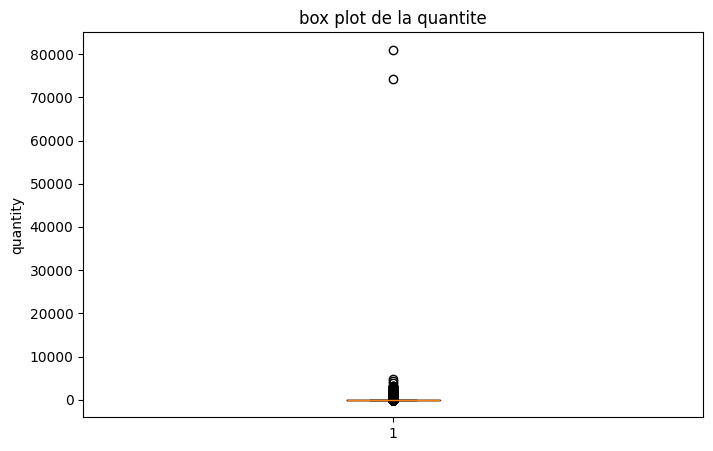

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.boxplot(df["Quantity"])
plt.title("box plot de la quantite")
plt.ylabel("quantity")

plt.show()

In [28]:
Q1 = df["Quantity"].quantile(0.25)
Q3 = df["Quantity"].quantile(0.75)

IQR = Q3 - Q1

borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)
print("Borne inférieure =", borne_inf)
print("Borne supérieure =", borne_sup)

Q1 = 2.0
Q3 = 12.0
IQR = 10.0
Borne inférieure = -13.0
Borne supérieure = 27.0


In [29]:
outliers_quantity =df[
    (df["Quantity"] < borne_inf) |
    (df["Quantity"] > borne_sup)
]


print("nombre des outliers",len(outliers_quantity))

nombre des outliers 25616


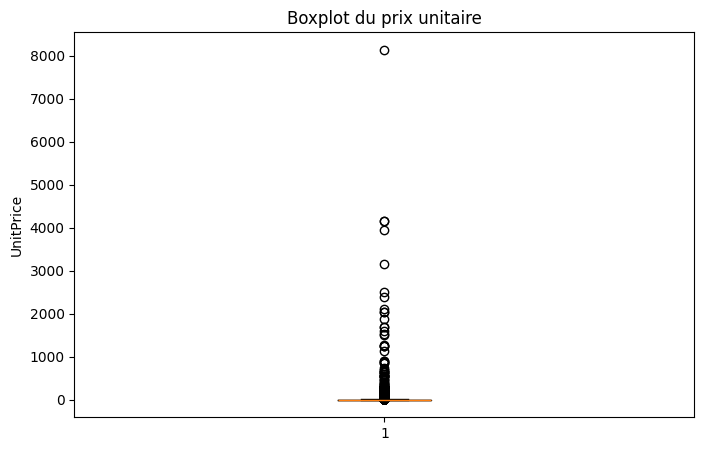

In [30]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["UnitPrice"])

plt.title("Boxplot du prix unitaire")
plt.ylabel("UnitPrice")

plt.show()

In [31]:
Q3 = df["UnitPrice"].quantile(0.75)
Q1 = df["UnitPrice"].quantile(0.25)

IQR = Q3 - Q1
lower =Q1 -1.5 * IQR
Upper = Q3 + 1.5 * IQR

print(Q3)
print(Q1)
print(IQR)
print(lower)
print(Upper)


3.75
1.25
2.5
-2.5
7.5


In [32]:
outliers_price = df[(df["UnitPrice"] < lower) |(df["UnitPrice"]> Upper)]
print(len(outliers_price))

34112


In [33]:
print((df["Quantity"]> 10000).sum())
print((df["UnitPrice"]> 1000).sum())

2
21


In [34]:
df[df["Quantity"] > 10000][
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08


In [35]:
print((df["StockCode"] == "M").sum())

279


In [36]:
categoriel_columns = df.select_dtypes(include="object").columns
print(categoriel_columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Country'], dtype='object')


In [37]:
df["Description"].value_counts()
df["Country"].value_counts()

,count
Country,
United Kingdom,349203
Germany,9025
France,8326
EIRE,7226
Spain,2479
Netherlands,2359
Belgium,2031
Switzerland,1841
Portugal,1453


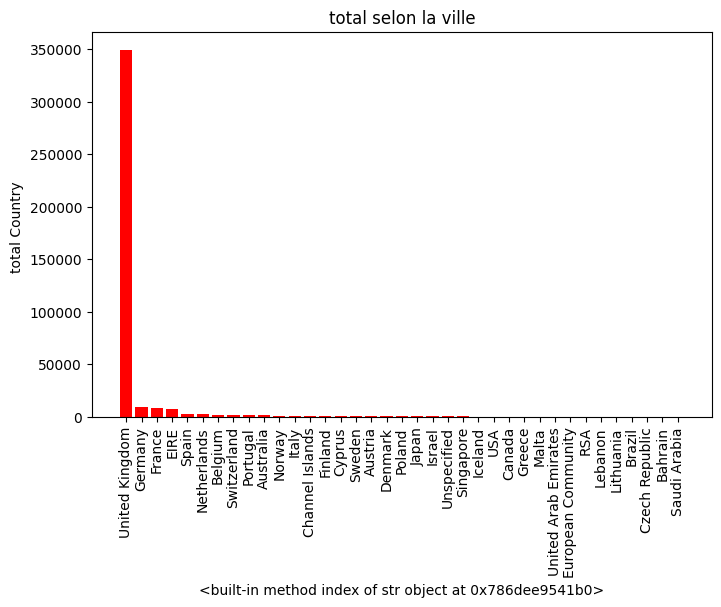

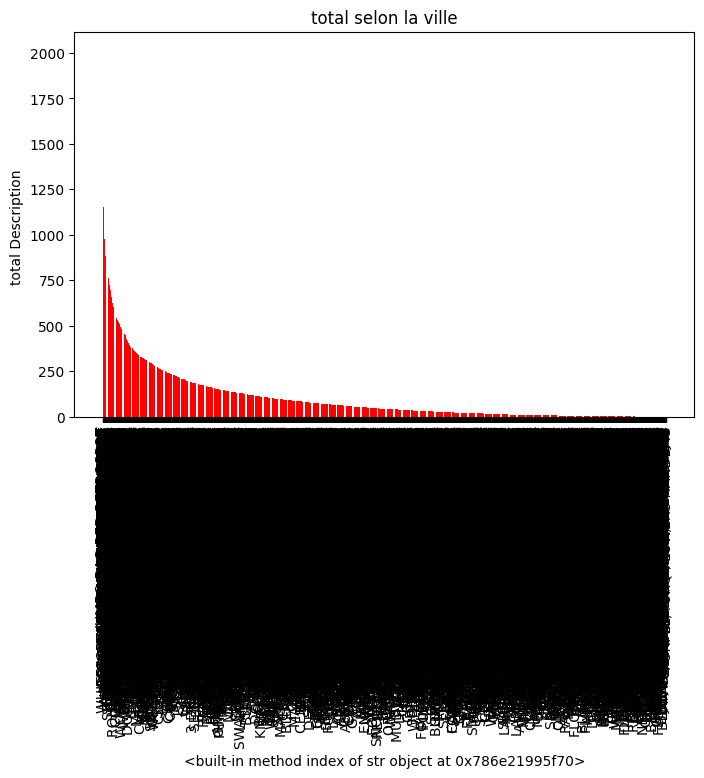

In [38]:
import matplotlib.pyplot as plt
categoriel_columns =["Country" ,"Description"]

for var in categoriel_columns:
    valeurCount =df[var].value_counts()
    plt.figure(figsize=(8,5))
    plt.bar(valeurCount.index,valeurCount.values,color="red")
    plt.title("total selon la ville")
    plt.xlabel(f"{var.index}")
    plt.ylabel(f"total {var} ")
    plt.xticks(rotation=90)
    plt.show()

# Partie 1 — Préparation et exploratio

In [10]:
import pandas as pd
df = pd.read_excel("/content/data (1).xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [11]:
df.shape

(541909, 8)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [13]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [14]:
df.describe(include="object")

,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


In [15]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [16]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [17]:
df.duplicated().sum()

np.int64(5268)

In [18]:
df =df.drop_duplicates()


In [19]:
df["Description"].value_counts()

,count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2357
REGENCY CAKESTAND 3 TIER,2189
JUMBO BAG RED RETROSPOT,2156
PARTY BUNTING,1720
LUNCH BAG RED RETROSPOT,1625
...,...
LIGHT DECORATION BATTERY OPERATED,1
RUBY GLASS CLUSTER NECKLACE,1
ANT SILVER TURQUOISE BOUDICCA RING,1


In [20]:
print("CustomerID manquant :", df["CustomerID"].isna().sum())
print("Description manquante :", df["Description"].isna().sum())
print("Quantity négative :", (df["Quantity"] < 0).sum())
print("UnitPrice négatif :", (df["UnitPrice"] < 0).sum())

CustomerID manquant : 135037
Description manquante : 1454
Quantity négative : 10587
UnitPrice négatif : 2


In [21]:
df = df.dropna(subset=["CustomerID"])

In [22]:
df[df["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [23]:
df =df[~df["InvoiceNo"].astype(str).str.startswith("C")]
print("Factures annulees :", 
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Quantites negatives :", 
      (df["Quantity"] < 0).sum())

Factures annulees : 0
Quantites negatives : 0


In [24]:
print("Quantite <= 0 :", (df["Quantity"] <= 0).sum())
print("Prix <= 0 :", (df["UnitPrice"] <= 0).sum())
print("CustomerID manquant :", df["CustomerID"].isnull().sum())
print("Doublons :", df.duplicated().sum())

Quantite <= 0 : 0
Prix <= 0 : 40
CustomerID manquant : 0
Doublons : 0


In [25]:
df = df[df["UnitPrice"] > 0]